# 🧪 Lab: ROC Curve & AUC

**Objectives**

By the end of this lab, students will be able to:

* Understand the difference between probabilities and labels
* Plot a ROC Curve
* Compute AUC score
* Choose an appropriate threshold
* Observe the effect of imbalanced datasets

# 1) Import Libraries

In [72]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix

# 2) Create Dataset (Imbalanced Data)

In [73]:
X, y = make_classification(
    n_samples=5000,
    n_features=10,
    weights=[0.95, 0.05],  # 5% positive class
    random_state=42
)

print("Class distribution:", np.bincount(y))

Class distribution: [4722  278]


# 3) Split Data

In [74]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# 4) Train Model

In [75]:
model = LogisticRegression()
model.fit(X_train, y_train)

LogisticRegression()

# 5) Get Probabilities

In [76]:
y_probs = model.predict_proba(X_test)[:, 1]
y_probs

array([0.00426866, 0.00322971, 0.67544255, ..., 0.01636264, 0.0067158 ,
       0.00280855])

# 6) ROC Curve (STUDENT TASK)

Task:
* Compute the ROC curve values (fpr, tpr, thresholds)
* Compute AUC score
* Plot the ROC curve

/tmp/ipykernel_8752/2595362756.py:14: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


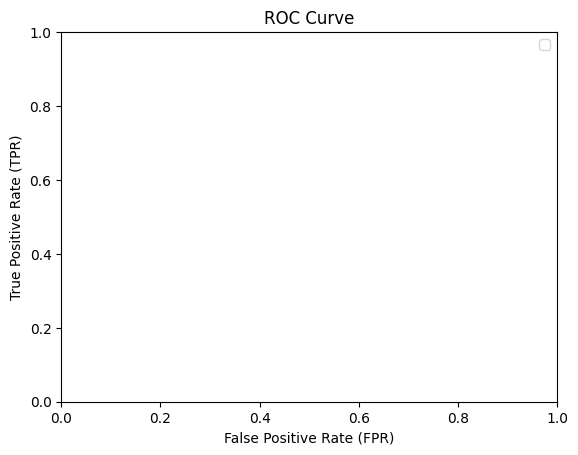

In [77]:
# TODO: compute fpr, tpr, thresholds

# TODO: compute AUC score

plt.figure()

# TODO: plot ROC curve (fpr vs tpr)

# TODO: plot diagonal reference line (random classifier)

plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.title("ROC Curve")
plt.legend()
plt.show()

# 7) Threshold Experiment (STUDENT TASK)

Task:

For each threshold:

* Convert probabilities into class predictions
* Compute confusion matrix
* Extract TP, FP, TN, FN
* Compute:
TPR (Recall)
FPR

In [78]:
thresholds_to_try = [0.2, 0.5, 0.8]

for t in thresholds_to_try:
    # TODO: convert probabilities to binary predictions
    y_pred = (y_probs >= t).astype(int)

    # TODO: compute confusion matrix
    from sklearn.metrics import confusion_matrix,classification_report
    cm = confusion_matrix(y_pred,y_test)


    # TODO: extract TN, FP, FN, TP
    tn, fp, fn, tp = cm.ravel()
    tpr=tp/(tp+fn)
    fpr=fp/(fp+tn)
    print(tpr,fpr)
    # TODO: compute TPR and FPR

    print(f"\nThreshold = {t}")
    print(f"TPR (Recall):{tpr}")
    print(f"FPR:{fpr}")

0.5636363636363636 0.02877697841726619

Threshold = 0.2
TPR (Recall):0.5636363636363636
FPR:0.02877697841726619
0.7931034482758621 0.053704962610469066

Threshold = 0.5
TPR (Recall):0.7931034482758621
FPR:0.053704962610469066
0.8571428571428571 0.06430006697923643

Threshold = 0.8
TPR (Recall):0.8571428571428571
FPR:0.06430006697923643
